# BRIDGE-Net | Brain CT preprocessing
Run cells in order. Each stage is independently executable once its prerequisites exist. Original files are read-only. Use a new output directory for each experiment. This notebook assumes 2-D, windowed CT images and independent binary object masks; it does not infer HU or patient identity from anonymised slice IDs. Review all flags before training. Experimental variants are off by default. Never use test results to select preprocessing.

Reviewed version: automatic mapping and non-destructive review templates; missing clinical decisions intentionally gate training. Install iterative-stratification if generating new splits. Review all project ontologies before accepting metadata.

## 00 • Dependencies

In [21]:
# Uncomment if needed, then restart the kernel if required.
# %pip install numpy pandas pillow opencv-python matplotlib tqdm scikit-learn torch ImageHash iterative-stratification
import json, hashlib, random, re, os, tempfile
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
from PIL import Image

from tqdm.auto import tqdm
import matplotlib.pyplot as plt
try:
    from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
except ImportError:
    MultilabelStratifiedShuffleSplit = None

def phash64(a):
    d=cv2.dct(cv2.resize(a,(32,32),interpolation=cv2.INTER_AREA).astype(np.float32))[:8,:8]
    bits=(d>np.median(d)).ravel(); return format(int("".join(str(int(x)) for x in bits),2),"016x")

## 01 • Configuration and reproducibility

In [22]:
ROOT = Path('labelbox_export_multi/merged_dataset').resolve()
OUT = Path('bridge_preprocessed_baseline').resolve()
SUPPORT = Path('labelbox_export_multi') / 'preprocessing_support'
PATIENT_CSV = SUPPORT / 'patient_mapping.csv' # sample_id, patient_id (globally pseudonymous)
CLASS_JSON = OUT / 'class_mapping.json' # {exact canonical label: integer channel index}
OBJECT_CSV = OUT / 'object_mapping.csv' # sample_id, mask_file, biomarker; relative to sample mask folder
REVIEW_CSV = SUPPORT / 'review_decisions.csv' # sample_id, include (0/1), reason
LABEL_STATUS_CSV = SUPPORT / 'label_status.csv' # sample_id, biomarker, known (0/1), optional if complete confirmed
CONFIRM_COMPLETE_ANNOTATIONS = False # set True ONLY after verifying exhaustive annotation
CONFIRM_PRIVACY_ORIENTATION_QA = False # set True after manual checks
METADATA_JSON = ROOT / "metadata.json"
# If metadata is outside the merged folder, set its path here.
if not METADATA_JSON.is_file() and (ROOT.parent / "metadata.json").is_file(): METADATA_JSON = ROOT.parent / "metadata.json"
APPROVE_SPATIAL_QA = False
ENABLE_AUGMENTATION = True
ENABLE_WEIGHTED_SAMPLING = True
ENABLE_CLASS_WEIGHTS = True
BATCH_SIZE = 4
PATCH_PROB = .5
PATCH_SIZE = 320
FLIP_PROB = 0.0
SIZE = 512
SEED = 42
ROI = True
ROI_MARGIN = 0.10
SKULL = False
CLAHE = False
DENOISE = False
HIST_MATCH = False
Z_SCORE = False
RGB = False
# Experimental skull extraction is a conservative PNG heuristic, not a validated clinical algorithm.
SKULL_THRESHOLD = 220 # 8-bit display intensity, NOT HU
SKULL_MIN_FRACTION = 0.15
assert ROOT.is_dir() and ROOT != OUT and ROOT not in OUT.parents and OUT not in ROOT.parents
OUT.mkdir(parents=True, exist_ok=True)
SUPPORT.mkdir(parents=True,exist_ok=True)
assert SIZE>0 and 0<=ROI_MARGIN<=1
def require_file(path, message):
    if not Path(path).is_file(): raise FileNotFoundError(f"{path}: {message}")
def template(path, frame):
    if not path.exists(): frame.to_csv(path,index=False)
    else: print(f"Preserving existing {path}")
random.seed(SEED); np.random.seed(SEED)
def save_json(path, data):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.NamedTemporaryFile(mode='w', dir=path.parent, delete=False) as f:
        json.dump(data,f,indent=2,allow_nan=False); name=f.name
    os.replace(name,path)
def read_json(p): return json.loads(Path(p).read_text())
def save_array(p,a):
    p=Path(p); p.parent.mkdir(parents=True,exist_ok=True)
    with tempfile.NamedTemporaryFile(dir=p.parent,delete=False) as f:
        np.save(f,a,allow_pickle=False); name=f.name
    os.replace(name,p)
def gray(p):
    with Image.open(p) as im:
        a=np.asarray(im)
        if a.dtype != np.uint8: raise ValueError(f'Non-8-bit input: {p}')
        if im.mode == 'P': a=np.asarray(im.convert('RGB'))
        if a.ndim==3 and not np.all(a[:,:,:3]==a[:,:,:1]): raise ValueError(f'Non-grayscale CT: {p}')
        return np.asarray(im.convert('L')).copy()
def mask_read(p):
    with Image.open(p) as im: a=np.asarray(im)
    if a.ndim != 2 or not set(np.unique(a)).issubset({0,1,255,False,True}):
        raise ValueError(f'Expected binary single-channel mask: {p}')
    return a>0
EXT={'.png','.bmp','.jpg','.jpeg'}

## 02 • Dataset integrity / format audit

In [23]:
rows=read_json(ROOT/'manifest.json'); records=[]; issues=[]
seen=set()
for r in tqdm(rows):
    sid='<unknown>'
    try:
        name=r['image_filename']; sid=Path(name).stem
        assert Path(name).name==name and re.fullmatch(r'.+-P-\d{5}',sid)
        assert sid not in seen; seen.add(sid)
        p=ROOT/'images'/name; a=gray(p)
        overlay=ROOT/'overlays'/(r.get('overlay_filename') or sid+'_overlay.png')
        with Image.open(overlay) as im: assert im.size==(a.shape[1],a.shape[0]); im.verify()
        folder=ROOT/'object_masks'/sid; assert folder.is_dir()
        records.append(dict(sample_id=sid,image_filename=name,source_project=r['source_project'],height=a.shape[0],width=a.shape[1]))
    except Exception as e: issues.append(dict(sample_id=sid,reason=repr(e)))
assert records, 'No valid images'
audit=pd.DataFrame(records); audit.to_csv(OUT/'inventory.csv',index=False)
pd.DataFrame(issues,columns=['sample_id','reason']).to_csv(OUT/'integrity_issues.csv',index=False)
print(len(audit),'valid;',len(issues),'issues; review before proceeding')
print(audit.groupby('source_project').size())
# Create review templates without overwriting existing decisions.
template(PATIENT_CSV,audit[['sample_id']].assign(patient_id=''))
template(REVIEW_CSV,audit[['sample_id']].assign(include='',reason=''))
# Mapping files are generated in stage 06. Patient IDs and review decisions must be supplied by the researcher.

100%|██████████| 4029/4029 [00:07<00:00, 571.89it/s]

3998 valid; 31 issues; review before proceeding
source_project
LBH     1135
MBRR    1014
MLRR    1849
dtype: int64
Preserving existing labelbox_export_multi/preprocessing_support/patient_mapping.csv
Preserving existing labelbox_export_multi/preprocessing_support/review_decisions.csv


## 03 • Privacy and orientation review

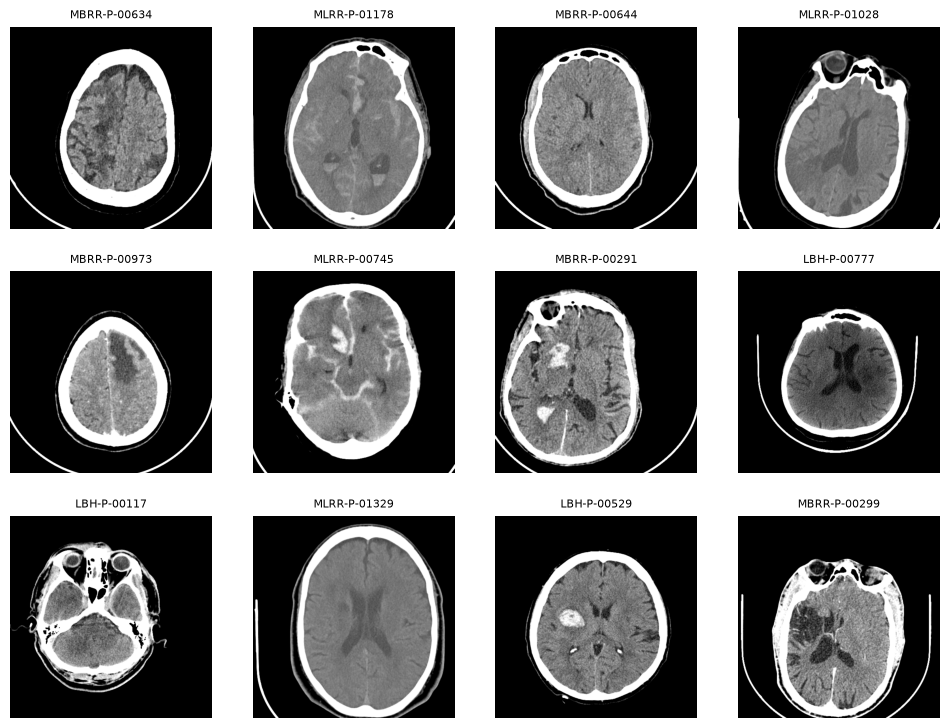

In [24]:
audit=pd.read_csv(OUT/'inventory.csv')
# Visual contact sheet: look for burned-in names, inconsistent orientation, scout views.
# Repeat with different seeds / inspect every sample in a controlled clinical review.
examples=audit.sample(min(12,len(audit)),random_state=SEED)
fig,axes=plt.subplots(3,4,figsize=(12,9))
for ax in axes.flat: ax.axis('off')
for ax, r in zip(axes.flat,examples.itertuples()):
    ax.imshow(gray(ROOT/'images'/r.image_filename),cmap='gray'); ax.set_title(r.sample_id,fontsize=8)
plt.show()
# Do not guess laterality from PNG. Correct orientation only using verified metadata,
# applying the exact same transform to masks. Export corrected source separately.

## 04 • Exact and near-duplicate detection

In [25]:
audit=pd.read_csv(OUT/'inventory.csv'); hashes=[]
for r in tqdm(audit.itertuples(),total=len(audit)):
    a=gray(ROOT/'images'/r.image_filename)
    h=hashlib.sha256(str(a.shape).encode()+a.tobytes()).hexdigest()
    ph=phash64(a)
    hashes.append((r.sample_id,h,ph))
hashes=pd.DataFrame(hashes,columns=['sample_id','sha256_pixels','phash']); hashes.to_csv(OUT/'hashes.csv',index=False)
hashes[hashes.duplicated('sha256_pixels',False)].to_csv(OUT/'exact_duplicates.csv',index=False)
# Band index: 5 disjoint bands guarantees candidates within Hamming distance 4.
buckets={}; pairs=[]
for r in tqdm(hashes.itertuples(),total=len(hashes)):
    v=int(r.phash,16); keys=[(i,(v>>shift)&((1<<width)-1)) for i,(shift,width) in enumerate([(0,13),(13,13),(26,13),(39,13),(52,12)])]
    candidates=set(j for k in keys for j in buckets.get(k,[]))
    for j in candidates:
        d=(v^int(hashes.iloc[j].phash,16)).bit_count()
        if d<=4: pairs.append((hashes.iloc[j].sample_id,r.sample_id,d))
    for k in keys: buckets.setdefault(k,[]).append(r.Index)
pd.DataFrame(pairs,columns=['sample_a','sample_b','distance']).to_csv(OUT/'near_duplicates.csv',index=False)
print('Review near duplicates; adjacent slices are not automatically discarded.')

100%|██████████| 3998/3998 [00:02<00:00, 1400.76it/s]

Review near duplicates; adjacent slices are not automatically discarded.


## 05 • Image quality flags

In [26]:
quality=[]
for r in tqdm(audit.itertuples(),total=len(audit)):
    a=gray(ROOT/'images'/r.image_filename)
    quality.append(dict(sample_id=r.sample_id,mean=float(a.mean()),std=float(a.std()),nonzero=float((a>0).mean()),laplacian_variance=float(cv2.Laplacian(a,cv2.CV_64F).var()),flag=bool(a.std()<3 or min(a.shape)<128)))
pd.DataFrame(quality).to_csv(OUT/'image_quality.csv',index=False)
# Thresholds are screening heuristics, not automatic clinical exclusions.

100%|██████████| 3998/3998 [00:13<00:00, 299.98it/s]


## 06 • Inspect annotation schema and prepare mapping

In [27]:
# Automatically derive mappings from Labelbox metadata and annotation files.
require_file(METADATA_JSON,"Copy your verified metadata.json to merged_dataset or set METADATA_JSON in configuration")
metadata = read_json(METADATA_JSON)
entries = sorted(metadata['classes'].items(), key=lambda item: item[1]['id'])
classes = {name: i for i, (name, info) in enumerate(entries)}
EXPECTED_CLASSES = len(classes)
assert EXPECTED_CLASSES > 0
assert len({info['id'] for _, info in entries}) == EXPECTED_CLASSES
assert metadata.get('num_foreground_classes', EXPECTED_CLASSES) == EXPECTED_CLASSES
aliases = read_json('label_aliases.json') if Path('label_aliases.json').exists() else {}
rows, issues = [], []
for sid in tqdm(audit.sample_id, desc='Reading object annotations'):
    folder = ROOT / 'object_masks' / sid
    try:
        info = read_json(folder / 'annotation_info.json')
        if info['image_stem'] != sid:
            raise ValueError('Image stem mismatch')
        items = info['objects']
        if info['num_objects'] != len(items):
            raise ValueError('Object count mismatch')
        sample_rows = []
        for obj in items:
            name = aliases.get(obj['class_name'], obj['class_name'])
            if name not in classes:
                raise ValueError(f'Unknown biomarker: {name}')
            if obj['download_status'] != 'downloaded':
                raise ValueError(f'Mask not downloaded: {obj["mask_filename"]}')
            filename = obj['mask_filename']
            mask = (folder / filename).resolve()
            if folder.resolve() not in mask.parents or not mask.is_file():
                raise ValueError(f'Missing or invalid mask: {filename}')
            sample_rows.append(dict(sample_id=sid, mask_file=filename, biomarker=name))
        if len({r['mask_file'] for r in sample_rows}) != len(sample_rows):
            raise ValueError('Duplicate mask filename')
        rows.extend(sample_rows)
    except Exception as exc:
        issues.append(dict(sample_id=sid, reason=str(exc)))
pd.DataFrame(issues, columns=['sample_id','reason']).to_csv(OUT/'object_mapping_issues.csv', index=False)
save_json(CLASS_JSON, classes)
pd.DataFrame(rows, columns=['sample_id','mask_file','biomarker']).to_csv(OBJECT_CSV, index=False)
print(f'{EXPECTED_CLASSES} classes; {len(rows)} object masks mapped')
print(f'Class mapping: {CLASS_JSON}\nObject mapping: {OBJECT_CSV}')
# Positive annotations are known; all other classes default to UNKNOWN, not negative.
positive={(r['sample_id'],r['biomarker']) for r in rows}
template(LABEL_STATUS_CSV,pd.DataFrame(((sid,b,int((sid,b) in positive)) for sid in audit.sample_id for b in classes),columns=['sample_id','biomarker','known']))
if issues: print(f'WARNING: {len(issues)} mapping errors; affected samples cannot be included until resolved.')


Reading object annotations: 100%|██████████| 3998/3998 [00:00<00:00, 5512.89it/s]


23 classes; 8532 object masks mapped
Class mapping: /Users/bash/Documents/Phd code/bash_phd/labelbox_export_segmentation/bridge_preprocessed_baseline/class_mapping.json
Object mapping: /Users/bash/Documents/Phd code/bash_phd/labelbox_export_segmentation/bridge_preprocessed_baseline/object_mapping.csv
Preserving existing labelbox_export_multi/preprocessing_support/label_status.csv


## 07 • Annotation harmonisation, object aggregation and multilabel encoding

In [29]:
classes=read_json(CLASS_JSON); assert len(classes)==EXPECTED_CLASSES and sorted(classes.values())==list(range(EXPECTED_CLASSES))
aliases=read_json('label_aliases.json') if Path('label_aliases.json').exists() else {}
objects=pd.read_csv(OBJECT_CSV,dtype=str); objects['biomarker']=objects.biomarker.astype(str)
assert set(objects.biomarker)<=set(classes), 'Unknown biomarker labels'
assert set(objects.sample_id)<=set(audit.sample_id)
assert not objects.duplicated(['sample_id','mask_file']).any()
status=pd.read_csv(LABEL_STATUS_CSV) if LABEL_STATUS_CSV.exists() and not CONFIRM_COMPLETE_ANNOTATIONS else None
assert CONFIRM_COMPLETE_ANNOTATIONS or status is not None, 'Supply label status or confirm complete annotation'
if status is not None:
    assert set(status.known)<= {0,1} and not status.duplicated(['sample_id','biomarker']).any()
    assert set(status.biomarker)<=set(classes)
    known_lookup={(r.sample_id,r.biomarker):int(r.known) for r in status.itertuples()}
groups={s:g for s,g in objects.groupby('sample_id')}; annotation_issues=[]; stats=[]
bad_mapping=set(pd.read_csv(OUT/'object_mapping_issues.csv').sample_id)
for r in tqdm(audit.itertuples(),total=len(audit)):
    try:
        if r.sample_id in bad_mapping: raise ValueError("Object mapping failed")
        y=np.zeros((len(classes),r.height,r.width),np.uint8); folder=(ROOT/'object_masks'/r.sample_id).resolve()
        group=groups.get(r.sample_id,objects.iloc[:0]); mapped=set()
        for obj in group.itertuples():
            p=(folder/obj.mask_file).resolve(); assert folder in p.parents
            m=mask_read(p); assert m.shape==y.shape[1:]; assert m.any(), 'Empty object mask'
            y[classes[obj.biomarker]] |= m; mapped.add(p)
        actual={p.resolve() for p in folder.rglob('*') if p.is_file() and p.suffix.lower() in EXT}
        assert actual==mapped, 'Unmapped or unexpected mask files; inspect mapping'
        known=np.array([int(CONFIRM_COMPLETE_ANNOTATIONS) if status is None else known_lookup.get((r.sample_id,k),0) for k in sorted(classes,key=classes.get)],np.uint8)
        assert not ((y.any((1,2))) & (known==0)).any(), 'Positive object marked unknown; resolve annotation status'
        save_array(OUT/'raw_masks'/f'{r.sample_id}.npy',y); save_array(OUT/'known'/f'{r.sample_id}.npy',known)
        stats.append(dict(sample_id=r.sample_id,positive_channels=int(y.any((1,2)).sum()),overlapping_pixels=int((y.sum(0)>1).sum())))
    except Exception as e: annotation_issues.append(dict(sample_id=r.sample_id,reason=repr(e)))
pd.DataFrame(annotation_issues,columns=['sample_id','reason']).to_csv(OUT/'annotation_issues.csv',index=False)
pd.DataFrame(stats,columns=['sample_id','positive_channels','overlapping_pixels']).to_csv(OUT/'annotation_stats.csv',index=False)
save_json(OUT/'class_mapping.json',classes)

100%|██████████| 3998/3998 [01:08<00:00, 58.04it/s] 


## 08 • Clinical annotation review and inclusion decisions

In [30]:
CONFIRM_PRIVACY_ORIENTATION_QA = True

In [32]:
review = pd.read_csv(REVIEW_CSV)

review["include"] = 1
review["reason"] = ""

review.to_csv(REVIEW_CSV, index=False)

print(f"Approved {len(review)} samples.")

Approved 3998 samples.


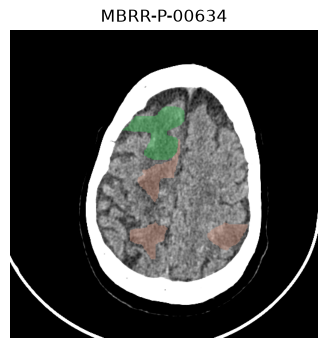

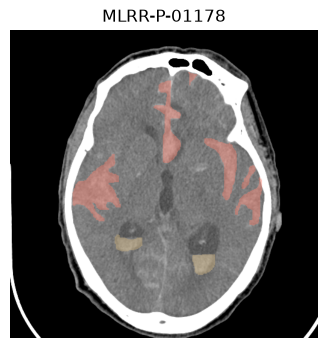

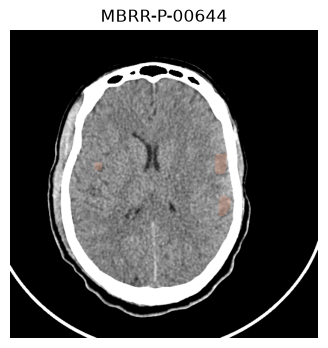

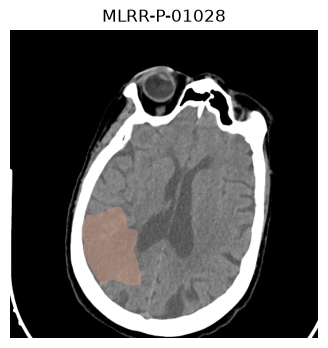

In [33]:
# Inspect masks over CT, including overlapping regions. Repeat across biomarkers/sites.
def show_overlay(a,y):
    rgb=np.repeat(a[:,:,None],3,axis=2).astype(float)
    rng=np.random.default_rng(42); colors=rng.integers(40,256,(len(y),3))
    count=y.sum(0); color=np.einsum('chw,ck->hwk',y.astype(float),colors)
    active=count>0; rgb[active]=0.55*rgb[active]+0.45*color[active]/count[active,None]
    return rgb.clip(0,255).astype(np.uint8)
valid=pd.read_csv(OUT/'annotation_stats.csv')
for sid in valid.sample(min(4,len(valid)),random_state=SEED).sample_id:
    r=audit.set_index('sample_id').loc[sid]; a=gray(ROOT/'images'/r.image_filename); y=np.load(OUT/'raw_masks'/f'{sid}.npy')
    plt.figure(figsize=(4,4)); plt.imshow(show_overlay(a,y)); plt.title(sid); plt.axis('off'); plt.show()
# Reviewer must record include/exclude decision for EVERY inventory sample, after privacy,
# quality, duplicate and annotation review. Do not include samples with unresolved defects.
assert CONFIRM_PRIVACY_ORIENTATION_QA, 'Complete privacy/orientation review first'
require_file(REVIEW_CSV,'Fill the generated review template'); review=pd.read_csv(REVIEW_CSV); assert not review.sample_id.duplicated().any() and set(review.sample_id)==set(audit.sample_id)
assert set(review.include)<= {0,1}, 'Fill every include field with 0 or 1 after review'
assert review.loc[review.include==0,'reason'].fillna('').astype(str).str.strip().ne('').all(), 'Provide exclusion reasons'
selected=audit.merge(review[['sample_id','include']],on='sample_id').query('include == 1').drop(columns='include')
assert set(selected.sample_id)<=set(valid.sample_id)
assert len(selected)>0, 'No samples approved'
selected.to_csv(OUT/'selected.csv',index=False)

## 09 • Patient-level, multilabel and hospital-aware splitting

In [35]:
selected = pd.read_csv(OUT / "selected.csv", dtype=str)

patients = pd.DataFrame({
    "sample_id": selected["sample_id"],
    "patient_id": selected["sample_id"]
})

patients.to_csv(PATIENT_CSV, index=False)

print(f"Generated {len(patients)} patient mappings.")
print(f"Saved to: {PATIENT_CSV}")

display(patients.head())

Generated 3998 patient mappings.
Saved to: labelbox_export_multi/preprocessing_support/patient_mapping.csv


,sample_id,patient_id
0,LBH-P-00001,LBH-P-00001
1,LBH-P-00002,LBH-P-00002
2,LBH-P-00003,LBH-P-00003
3,LBH-P-00004,LBH-P-00004
4,LBH-P-00005,LBH-P-00005


In [37]:
selected=pd.read_csv(OUT/'selected.csv'); require_file(PATIENT_CSV,'Fill real pseudonymous patient IDs in the generated template'); patients=pd.read_csv(PATIENT_CSV,dtype=str)
assert not patients.sample_id.duplicated().any()
df=selected.merge(patients[['sample_id','patient_id']],on='sample_id',how='left',validate='one_to_one')
assert df.patient_id.notna().all() and df.patient_id.str.strip().ne('').all(), 'No patient IDs may be guessed'
# Same patient across sites must share the same pseudonym.
presence_rows=[]
for sid in df.sample_id:
    y=np.load(OUT/'raw_masks'/f'{sid}.npy'); presence_rows.append(y.any((1,2)).astype(int))
df[list(classes)]=np.asarray(presence_rows)
pres=df.groupby('patient_id')[list(classes)].max(); sites=pd.crosstab(df.patient_id,df.source_project).gt(0).astype(int).reindex(pres.index)
Y=np.concatenate([pres.to_numpy(),sites.to_numpy()],axis=1); ids=pres.index.to_numpy()
assert len(ids)>=3, 'At least three independent patients are required'
# Preserve a reviewed partition across all preprocessing variants.
fixed=SUPPORT/'fixed_patient_splits.csv'
if fixed.exists():
    f=pd.read_csv(fixed,dtype=str); assert not f.patient_id.duplicated().any() and set(f.patient_id)==set(ids), 'Patient cohort changed: review and version fixed splits'
    lookup=dict(zip(f.patient_id,f.split)); assert set(lookup.values())=={'train','val','test'}
else:
    if MultilabelStratifiedShuffleSplit is None:
        raise ImportError('Install iterative-stratification (see dependency cell) to generate patient splits')
    hold=max(2,min(len(ids)-1,round(.30*len(ids))))
    a,b=next(MultilabelStratifiedShuffleSplit(n_splits=1,test_size=hold,random_state=SEED).split(Y,Y))
    c,d=next(MultilabelStratifiedShuffleSplit(n_splits=1,test_size=max(1,len(b)//2),random_state=SEED+1).split(Y[b],Y[b]))
    parts={'train':ids[a],'val':ids[b[c]],'test':ids[b[d]]}; lookup={p:k for k,v in parts.items() for p in v}
df['split']=df.patient_id.map(lookup)
parts=['train','val','test']
assert set(df.split)==set(parts), 'Empty partition'
assert df.groupby('patient_id').split.nunique().max()==1
# Identical pixels must not cross partitions, even if patient IDs differ.
# h=df.merge(pd.read_csv(OUT/'hashes.csv'),on='sample_id'); assert h.groupby('sha256_pixels').split.nunique().max()==1, 'Resolve cross-split duplicates before continuing'

# =====================================================
# RESOLVE CROSS-PARTITION DUPLICATES
# =====================================================

from collections import Counter

hashes = pd.read_csv(OUT / "hashes.csv")

h = df.merge(
    hashes[["sample_id", "sha256_pixels"]],
    on="sample_id",
    how="left",
    validate="one_to_one"
)

assert h["sha256_pixels"].notna().all(), "Missing image hashes"

# Union-Find: group patients connected by duplicate images
parent = {
    pid: pid for pid in df["patient_id"].unique()
}


def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]

    return x


def union(a, b):
    root_a = find(a)
    root_b = find(b)

    if root_a != root_b:
        parent[root_b] = root_a


# Connect patients sharing identical CT images
for _, group in h.groupby("sha256_pixels"):

    patient_ids = group["patient_id"].unique()

    for pid in patient_ids[1:]:
        union(patient_ids[0], pid)


# Create connected patient groups
df["duplicate_group"] = df["patient_id"].map(find)

changes = []

# Assign each connected group to one partition
for group_id, group in df.groupby("duplicate_group"):

    if group["split"].nunique() <= 1:
        continue

    # Retain the partition containing most images
    target_split = Counter(group["split"]).most_common(1)[0][0]

    for _, row in group.iterrows():

        if row["split"] != target_split:

            changes.append({
                "sample_id": row["sample_id"],
                "patient_id": row["patient_id"],
                "old_split": row["split"],
                "new_split": target_split
            })

    df.loc[
        df["duplicate_group"] == group_id,
        "split"
    ] = target_split


# =====================================================
# VALIDATE CORRECTED PARTITIONS
# =====================================================

h = df.merge(
    hashes[["sample_id", "sha256_pixels"]],
    on="sample_id",
    validate="one_to_one"
)

assert (
    h.groupby("sha256_pixels")["split"].nunique().max() == 1
), "Cross-partition duplicates remain"

assert (
    df.groupby("patient_id")["split"].nunique().max() == 1
), "Patient leakage detected"

assert set(df["split"]) == {"train", "val", "test"}, (
    "Duplicate resolution resulted in an empty partition"
)

pd.DataFrame(
    changes,
    columns=[
        "sample_id",
        "patient_id",
        "old_split",
        "new_split"
    ]
).to_csv(
    OUT / "duplicate_resolution_report.csv",
    index=False
)

# Update patient-to-partition mapping
lookup = (
    df[["patient_id", "split"]]
    .drop_duplicates()
    .set_index("patient_id")["split"]
    .to_dict()
)

print("Cross-partition duplicates successfully resolved.")
print(f"Reassigned images: {len(changes)}")

print("\nUpdated dataset distribution:")
print(df["split"].value_counts())

print("\nPatient distribution:")
print(df.groupby("split")["patient_id"].nunique())
# if not fixed.exists(): pd.DataFrame({'patient_id':list(lookup),'split':list(lookup.values())}).to_csv(fixed,index=False)
# Preserve the previous partition assignments
if fixed.exists():
    import shutil

    shutil.copy2(
        fixed,
        fixed.with_name("previous_" + fixed.name)
    )

# Save corrected patient partitions
pd.DataFrame({
    "patient_id": list(lookup),
    "split": list(lookup.values())
}).to_csv(fixed, index=False)
for p in parts: save_json(OUT/'splits'/f'{p}.json',df.loc[df.split==p,'sample_id'].tolist())
df[['sample_id','image_filename','source_project','patient_id','split']].to_csv(OUT/'split_manifest.csv',index=False)
df.groupby('split')[list(classes)].sum().to_csv(OUT/'split_class_counts.csv'); print(df.groupby('split')[list(classes)].sum()); print(df.groupby('split').patient_id.nunique())
# Rare classes may be absent from some splits; report rather than promise perfect stratification.

Cross-partition duplicates successfully resolved.
Reassigned images: 205

Updated dataset distribution:
split
train    2810
test      597
val       591
Name: count, dtype: int64

Patient distribution:
split
test      597
train    2810
val       591
Name: patient_id, dtype: int64
       acute_on_chronic_sdh  basal_ganglia_hemorrhage  cerebral_edema  \
split                                                                   
test                      0                        34              88   
train                     1                       161             414   
val                       1                        28              93   

       chronic_sdh  cortical_involvement  hemorrhagic_transformation  \
split                                                                  
test             0                    78                          50   
train            1                   421                         253   
val              0                    79                          

## 10 • Skull stripping — optional experimental heuristic

In [38]:
def extract_brain(a):
    # Conservative enclosed skull cavity heuristic; fails on open skull / some slices.
    bone=(a>=SKULL_THRESHOLD).astype(np.uint8)
    bone=cv2.morphologyEx(bone,cv2.MORPH_CLOSE,np.ones((5,5),np.uint8))
    free=(1-bone).astype(np.uint8); num,lab,stats,_=cv2.connectedComponentsWithStats(free)
    border=set(np.concatenate([lab[0],lab[-1],lab[:,0],lab[:,-1]]))
    candidates=[i for i in range(1,num) if i not in border]
    if not candidates: return np.ones_like(a,bool), 'fallback_no_closed_cavity'
    i=max(candidates,key=lambda j:stats[j,cv2.CC_STAT_AREA]); m=lab==i
    if m.mean()<SKULL_MIN_FRACTION: return np.ones_like(a,bool),'fallback_small_cavity'
    m=cv2.dilate(m.astype(np.uint8),np.ones((9,9),np.uint8))>0
    return m,'heuristic_review_required'
# Never use annotations to generate the brain mask or alter the image at inference.

## 11 • Anatomical ROI extraction

In [39]:
def roi_box(a):
    # Image-only head bounding box; retain all nonzero foreground conservatively.
    h,w=a.shape; yy,xx=np.where(a>0)
    if not len(xx): return (0,0,w,h)
    x0,x1=int(xx.min()),int(xx.max())+1; y0,y1=int(yy.min()),int(yy.max())+1
    mx=int(np.ceil((x1-x0)*ROI_MARGIN)); my=int(np.ceil((y1-y0)*ROI_MARGIN))
    return max(0,x0-mx),max(0,y0-my),min(w,x1+mx),min(h,y1+my)

## 12 • Spatial standardisation and reversible geometry

In [40]:
def spatial(a,y,box):
    x0,y0,x1,y1=box; a=a[y0:y1,x0:x1]; y=y[:,y0:y1,x0:x1]
    h,w=a.shape; scale=SIZE/max(h,w); nh=max(1,round(h*scale)); nw=max(1,round(w*scale))
    top=(SIZE-nh)//2; left=(SIZE-nw)//2
    out=np.zeros((SIZE,SIZE),np.uint8); masks=np.zeros((len(y),SIZE,SIZE),np.uint8)
    out[top:top+nh,left:left+nw]=cv2.resize(a,(nw,nh),interpolation=cv2.INTER_AREA if scale<1 else cv2.INTER_LINEAR)
    for i,m in enumerate(y): masks[i,top:top+nh,left:left+nw]=cv2.resize(m,(nw,nh),interpolation=cv2.INTER_NEAREST)
    return out,masks,dict(box=list(box),resized=[nh,nw],padding=[top,left])
def restore_prediction(pred,geometry,original_shape):
    x0,y0,x1,y1=geometry['box']; nh,nw=geometry['resized']; top,left=geometry['padding']
    result=np.zeros((len(pred),*original_shape),np.float32)
    for i,p in enumerate(pred): result[i,y0:y1,x0:x1]=cv2.resize(p[top:top+nh,left:left+nw].astype(np.float32),(x1-x0,y1-y0),interpolation=cv2.INTER_LINEAR)
    return result

## 13 • Experimental CLAHE, denoising and histogram matching

In [41]:
def enhance(a):
    foreground=a>0; b=a.copy()
    if DENOISE: b=cv2.GaussianBlur(b,(3,3),0.5)
    if CLAHE: b=cv2.createCLAHE(clipLimit=2.0,tileGridSize=(8,8)).apply(b)
    b[~foreground]=0
    return b
def cdf(a):
    hist=np.bincount(a[a>0],minlength=256).astype(float)
    return hist
split_df=pd.read_csv(OUT/'split_manifest.csv'); train=split_df.query('split == "train"')
ref_hist=np.zeros(256)
if HIST_MATCH:
    for r in tqdm(train.itertuples(),total=len(train)):
        a=gray(ROOT/'images'/r.image_filename); box=roi_box(a) if ROI else (0,0,a.shape[1],a.shape[0])
        if SKULL: a[~extract_brain(a)[0]]=0
        x0,y0,x1,y1=box; ref_hist+=cdf(enhance(a)[y0:y1,x0:x1])
    assert ref_hist.sum()>0
    ref_cdf=np.cumsum(ref_hist)/ref_hist.sum()
    save_array(OUT/'training_histogram.npy',ref_hist)
def match_hist(a):
    if not HIST_MATCH or not (a>0).any(): return a
    h=cdf(a); source=np.cumsum(h)/h.sum(); lut=np.searchsorted(ref_cdf,source).clip(1,255).astype(np.uint8); lut[0]=0
    return lut[a]

## 14 • Apply image transforms, masks, overlays and spatial QA

In [42]:
geometry={}; qa=[]
for r in tqdm(split_df.itertuples(),total=len(split_df)):
    sid=r.sample_id; original=gray(ROOT/'images'/r.image_filename); y=np.load(OUT/'raw_masks'/f'{sid}.npy'); a=original.copy()
    brain,brain_status=extract_brain(a) if SKULL else (np.ones_like(a,bool),'disabled')
    outside=(y[:,~brain]).sum(1); a[~brain]=0
    # Compute ROI from original image to avoid inadvertently cropping peripheral pathology.
    box=roi_box(original) if ROI else (0,0,a.shape[1],a.shape[0]); x0,y0,x1,y1=box
    before=y.sum((1,2)); cropped=y[:,y0:y1,x0:x1].sum((1,2)); a=match_hist(enhance(a)); a,m,g=spatial(a,y,box)
    lost=np.where((before>0)&(~m.any((1,2))))[0].tolist()
    for folder in ['images','brain_masks','overlays']: (OUT/folder).mkdir(exist_ok=True)
    Image.fromarray(a).save(OUT/'images'/f'{sid}.png'); Image.fromarray(brain.astype(np.uint8)*255).save(OUT/'brain_masks'/f'{sid}.png')
    Image.fromarray(show_overlay(a,m)).save(OUT/'overlays'/f'{sid}_overlay.png'); save_array(OUT/'multilabel_masks'/f'{sid}.npy',m)
    geometry[sid]={**g,'original_shape':list(original.shape)}
    qa.append(dict(sample_id=sid,brain_status=brain_status,annotated_pixels_outside_brain=int(outside.sum()),cropped_annotation_pixels=int((before-cropped).sum()),lost_channels=str(lost),flag=bool(outside.any() or (before!=cropped).any() or lost or (SKULL and brain_status.startswith('fallback')))))
save_json(OUT/'geometry.json',geometry); pd.DataFrame(qa).to_csv(OUT/'spatial_qa.csv',index=False)
print(pd.DataFrame(qa).flag.value_counts()); print('Review all flagged cases and skull masks before training.')

100%|██████████| 3998/3998 [04:17<00:00, 15.51it/s]

flag
False    3998
Name: count, dtype: int64
Review all flagged cases and skull masks before training.


## 15 • Intensity normalisation and channel configuration

In [43]:
# Fit optional z-score using TRAIN ONLY; default [0,1] scaling.
mu=0.; sigma=1.
if Z_SCORE:
    total=sq=count=0
    for sid in train.sample_id:
        a=gray(OUT/'images'/f'{sid}.png').astype(np.float64)/255
        total+=a.sum(); sq+=(a*a).sum(); count+=a.size
    mu=total/count; sigma=max(np.sqrt(max(0,sq/count-mu**2)),1e-6)
save_json(OUT/'normalisation.json',dict(mean=float(mu),std=float(sigma),rgb=RGB))
def normalise(a):
    a=(a.astype(np.float32)/255-mu)/sigma
    return np.repeat(a[None],3 if RGB else 1,axis=0)

## 16 • Training-only frequency, pixel distribution and relationship analysis

100%|██████████| 2810/2810 [00:17<00:00, 158.28it/s]


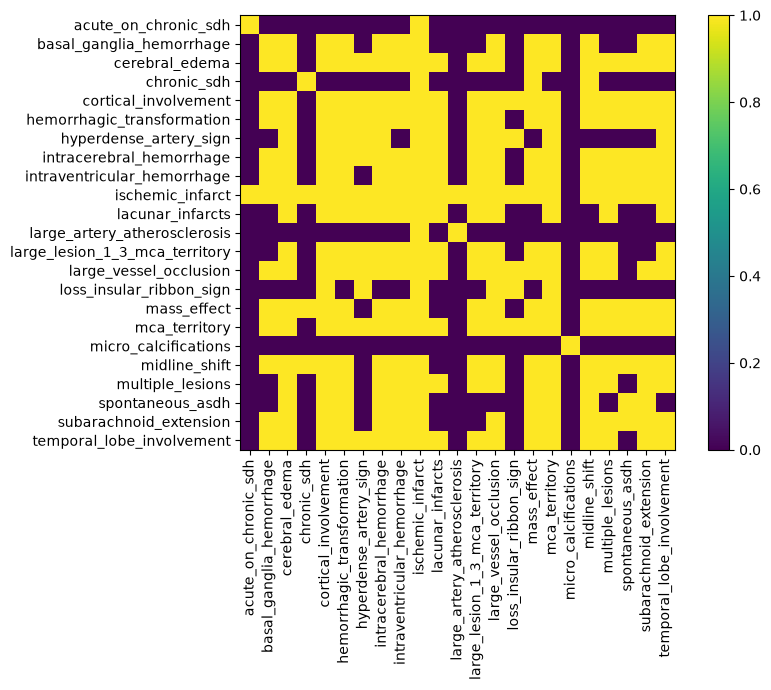

                         biomarker  positive_slices  known_slices  \
0             acute_on_chronic_sdh              1.0           1.0   
1         basal_ganglia_hemorrhage            161.0         161.0   
2                   cerebral_edema            414.0         414.0   
3                      chronic_sdh              1.0           1.0   
4             cortical_involvement            421.0         421.0   
5       hemorrhagic_transformation            253.0         253.0   
6           hyperdense_artery_sign             25.0          25.0   
7         intracerebral_hemorrhage            654.0         654.0   
8      intraventricular_hemorrhage            370.0         370.0   
9                 ischemic_infarct           1403.0        1403.0   
10                lacunar_infarcts            171.0         171.0   
11    large_artery_atherosclerosis              1.0           1.0   
12  large_lesion_1_3_mca_territory            188.0         188.0   
13          large_vessel_occlusion

In [44]:
K=len(classes); names=sorted(classes,key=classes.get); freq=np.zeros(K); pixels=np.zeros(K); known_count=np.zeros(K); pair=np.zeros((K,K)); eligible=np.zeros((K,K)); overlap=np.zeros((K,K)); union=np.zeros((K,K)); presence=[]
for sid in tqdm(train.sample_id):
    y=np.load(OUT/'multilabel_masks'/f'{sid}.npy').astype(bool); k=np.load(OUT/'known'/f'{sid}.npy').astype(bool); p=y.any((1,2)) & k
    freq+=p; pixels+=y.sum((1,2))*k; known_count+=k; pair+=np.outer(p,p); eligible+=np.outer(k,k); presence.append(p)
    for i in range(K):
        for j in range(i,K):
            if k[i] and k[j]:
                v=(y[i]&y[j]).sum(); u=(y[i]|y[j]).sum(); overlap[i,j]+=v; union[i,j]+=u
                if i!=j: overlap[j,i]+=v; union[j,i]+=u
co=np.divide(pair,eligible,out=np.zeros_like(pair),where=eligible>0); iou=np.divide(overlap,union,out=np.zeros_like(overlap),where=union>0)
for name,mat in [('cooccurrence',co),('spatial_overlap_iou',iou),('pair_known_counts',eligible)]: pd.DataFrame(mat,index=names,columns=names).to_csv(OUT/f'{name}.csv')
frequency=pd.DataFrame(dict(biomarker=names,positive_slices=freq,known_slices=known_count,foreground_pixels=pixels)); frequency.to_csv(OUT/'class_distribution.csv',index=False)
plt.figure(figsize=(9,7)); plt.imshow(co,vmin=0,vmax=1); plt.xticks(range(K),names,rotation=90); plt.yticks(range(K),names); plt.colorbar(); plt.tight_layout(); plt.show()
print(frequency); print('Zero-positive training classes:',[names[i] for i in np.where(freq==0)[0]])

## 17 • Class weights and class-aware sampling

In [45]:
import torch
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
# Capped inverse-frequency weights; absent classes receive zero positive weight.
if not (freq>0).all(): print('WARNING: no training positives for:', [names[i] for i in np.where(freq==0)[0]])
weights=np.where(freq>0,np.clip(np.sqrt(max(1,freq.max())/np.maximum(freq,1)),1,6),1).astype(np.float32)
pos_weights=np.clip((known_count-freq)/np.maximum(freq,1),1,10).astype(np.float32)
if not ENABLE_CLASS_WEIGHTS: weights[:]=1; pos_weights[:]=1
# Sample weight uses maximum rare-class weight, not sum, to avoid rewarding many labels.
sample_weights=np.array([max(1,float(weights[p].max())) if p.any() else 1 for p in presence])
save_json(OUT/'class_weights.json',dict(class_weights=weights.tolist(),bce_pos_weights=pos_weights.tolist()))
pd.DataFrame(dict(sample_id=train.sample_id,weight=sample_weights)).to_csv(OUT/'sampling_weights.csv',index=False)

## 18 • Rare-biomarker patch sampling and online augmentation

In [46]:
RARE_IDS=np.array([i for i in np.argsort(freq) if freq[i]>0][:max(1,K//4)],dtype=int)
def augment(a,y,rng):
    original_a,original_y=a.copy(),y.copy()
    # Label-guided crops ONLY during training. Return to fixed input dimensions.
    available=[i for i in RARE_IDS if y[i].any()]
    if available and rng.random()<PATCH_PROB:
        i=int(rng.choice(available)); yy,xx=np.where(y[i]); j=int(rng.integers(len(xx))); h,w=a.shape; s=min(PATCH_SIZE,h,w)
        x=int(np.clip(xx[j]-s//2,0,w-s)); z=int(np.clip(yy[j]-s//2,0,h-s)); a,y,_=spatial(a,y,(x,z,x+s,z+s))
    h,w=a.shape; M=cv2.getRotationMatrix2D((w/2,h/2),float(rng.uniform(-10,10)),float(rng.uniform(.9,1.1))); M[:,2]+=rng.uniform(-.05,.05,2)*[w,h]
    a=cv2.warpAffine(a,M,(w,h),flags=cv2.INTER_LINEAR,borderValue=0)
    y=np.stack([cv2.warpAffine(m,M,(w,h),flags=cv2.INTER_NEAREST,borderValue=0) for m in y])
    if rng.random()<FLIP_PROB: a=a[:,::-1]; y=y[:,:,::-1]
    if np.any(original_y.any((1,2)) & ~y.any((1,2))): a,y=original_a,original_y
    foreground=a>0; v=a.astype(np.float32)/255; v=np.clip(v*rng.uniform(.9,1.1)+rng.uniform(-.05,.05),0,1)**rng.uniform(.9,1.1); v+=rng.normal(0,.01,v.shape); v[~foreground]=0
    return (np.clip(v,0,1)*255).astype(np.uint8),y.copy()

## 19 • Final QA and explicit experiment approval

In [48]:
flags = pd.read_csv(OUT / "spatial_qa.csv")

problematic = flags[
    (flags["cropped_annotation_pixels"] > 0)
    | (flags["lost_channels"] != "[]")
    | (flags["annotated_pixels_outside_brain"] > 0)
]

print("========== SPATIAL QA SUMMARY ==========")
print(f"Total processed images: {len(flags)}")
print(f"Problematic images: {len(problematic)}")
print(f"Images without detected issues: {len(flags) - len(problematic)}")

if problematic.empty:
    print("\nPASS: No detected loss of annotated content.")
else:
    print("\nWARNING: Some annotations may have been affected.")
    display(problematic)

problematic.to_csv(
    OUT / "spatial_qa_problematic.csv",
    index=False
)

========== SPATIAL QA SUMMARY ==========
Total processed images: 3998
Problematic images: 0
Images without detected issues: 3998

PASS: No detected loss of annotated content.


In [49]:
APPROVE_SPATIAL_QA = True

In [50]:
issues=[]
for r in tqdm(split_df.itertuples(),total=len(split_df)):
    sid=r.sample_id
    try:
        a=gray(OUT/'images'/f'{sid}.png'); y=np.load(OUT/'multilabel_masks'/f'{sid}.npy'); known=np.load(OUT/'known'/f'{sid}.npy')
        assert a.shape==(SIZE,SIZE) and y.shape==(K,SIZE,SIZE) and known.shape==(K,)
        assert y.dtype==np.uint8 and y.max()<=1 and set(known)<= {0,1}
        assert np.isfinite(normalise(a)).all()
    except Exception as e: issues.append(dict(sample_id=sid,reason=repr(e)))
save_json(OUT/'final_issues.json',issues); assert not issues, 'Resolve final QA failures'
flags=pd.read_csv(OUT/'spatial_qa.csv'); print(flags[flags.flag]);
# Set True only after reviewing all transformed samples/flags and correcting failures.
assert APPROVE_SPATIAL_QA, 'Set APPROVE_SPATIAL_QA=True in configuration only after reviewing transformed images and flags'
assert not (flags.cropped_annotation_pixels.gt(0) | flags.lost_channels.ne('[]') | flags.annotated_pixels_outside_brain.gt(0)).any(), 'Preprocessing removed annotated content: use a safer configuration before training'
save_json(OUT/'preprocessing_config.json',dict(size=SIZE,seed=SEED,roi=ROI,roi_margin=ROI_MARGIN,skull=SKULL,skull_threshold=SKULL_THRESHOLD,clahe=CLAHE,denoise=DENOISE,hist_match=HIST_MATCH,z_score=Z_SCORE,rgb=RGB,patch_probability=PATCH_PROB,patch_size=PATCH_SIZE,flip_probability=FLIP_PROB))

100%|██████████| 3998/3998 [00:22<00:00, 180.46it/s]

Empty DataFrame
Columns: [sample_id, brain_status, annotated_pixels_outside_brain, cropped_annotation_pixels, lost_channels, flag]
Index: []


## 20 • PyTorch datasets, loaders and masked multilabel loss

In [51]:
class BridgeDataset(Dataset):
    def __init__(self,split): self.ids=read_json(OUT/'splits'/f'{split}.json'); self.training=split=='train'
    def __len__(self): return len(self.ids)
    def __getitem__(self,i):
        sid=self.ids[i]; a=gray(OUT/'images'/f'{sid}.png'); y=np.load(OUT/'multilabel_masks'/f'{sid}.npy'); k=np.load(OUT/'known'/f'{sid}.npy')
        if self.training and ENABLE_AUGMENTATION: a,y=augment(a,y,np.random.default_rng(np.random.randint(0,2**32-1)))
        return torch.from_numpy(normalise(a)),torch.from_numpy(y.astype(np.float32)),torch.from_numpy(k.astype(np.float32)),sid
torch.manual_seed(SEED); datasets={p:BridgeDataset(p) for p in ['train','val','test']}
weight_by_id=dict(zip(train.sample_id,sample_weights)); generator=torch.Generator().manual_seed(SEED)
sampler=WeightedRandomSampler([weight_by_id[s] for s in datasets['train'].ids],len(datasets['train']),replacement=True,generator=generator)
loaders={p:DataLoader(ds,batch_size=BATCH_SIZE,sampler=sampler if p=='train' and ENABLE_WEIGHTED_SAMPLING else None,shuffle=(p=='train' and not ENABLE_WEIGHTED_SAMPLING),num_workers=0) for p,ds in datasets.items()}
def masked_dice_bce(logits,target,known):
    import torch.nn.functional as F
    valid=known[:,:,None,None]; pw=torch.as_tensor(pos_weights,device=logits.device)[None,:,None,None]
    bce=F.binary_cross_entropy_with_logits(logits,target,pos_weight=pw,reduction='none'); bce=(bce*valid).sum()/(valid.sum()*target.shape[-1]*target.shape[-2]).clamp_min(1)
    prob=logits.sigmoid(); inter=(prob*target).sum((2,3)); denom=(prob+target).sum((2,3)); dice=1-(2*inter+1e-6)/(denom+1e-6)
    w=torch.as_tensor(weights,device=logits.device)[None,:]*known
    return bce+(dice*w).sum()/w.sum().clamp_min(1)
x,y,k,ids=next(iter(loaders['train'])); print(x.shape,y.shape,k.shape); print('Smoke loss:',masked_dice_bce(torch.zeros_like(y),y,k).item())
# BRIDGE-Net should emit raw logits [B,K,H,W]; sigmoid only for predictions.

torch.Size([4, 1, 512, 512]) torch.Size([4, 23, 512, 512]) torch.Size([4, 23])
Smoke loss: 1.5924543142318726


## 21 • Optional hard-example sampling for later training epochs

In [52]:
def hard_example_sampler(loss_by_id, factor=1.5):
    # Supply training-only per-sample losses from a completed epoch; never validation/test.
    assert set(loss_by_id)<=set(datasets['train'].ids)
    values=np.array([loss_by_id.get(s,0.) for s in datasets['train'].ids],float)
    assert np.isfinite(values).all() and (values>=0).all()
    scale=np.quantile(values,.9); multiplier=1+factor*np.clip(values/max(scale,1e-8),0,1)
    return WeightedRandomSampler([weight_by_id[s]*m for s,m in zip(datasets['train'].ids,multiplier)],len(values),replacement=True)

## 22 • Ablation study protocol
Use the same reviewed sample IDs and fixed patient splits for each variant. Copy configuration and split manifest to each experiment directory or verify exact equality after deterministic regeneration. Start with ROI=False, SKULL=False, CLAHE=False, DENOISE=False, HIST_MATCH=False, Z_SCORE=False. Then evaluate ROI, skull stripping, both, CLAHE, denoising and histogram matching independently; compare augmentation, sampling and weighting separately. Use validation Dice for selection and keep the test set untouched. A validated CT brain extraction model is preferable to the optional heuristic; inspect especially SAH, subdural and cortical labels. Do not use the heuristic on clinical decisions. Compare per-class Dice, macro Dice, IoU, sensitivity, precision and HD95 (pixel units unless physical spacing is available); define absent-class handling in advance. Relationship priors are exported, not automatically integrated into BRIDGE-Net. No accuracy improvement is guaranteed.